# EDA -- Telco Customer Churn

Objectif : comprendre la structure du dataset, detecter les valeurs
manquantes/aberrantes, observer les distributions et les correlations
avant de definir la strategie de nettoyage et de feature engineering.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.preprocessing import clean_data, load_data

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df_raw = load_data("../data/raw/telco_churn.csv")
print(df_raw.shape)
df_raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Structure et types

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` est lu comme texte (`object`) alors qu'il devrait etre
numerique -- signe de valeurs non numeriques dans la colonne.

In [4]:
non_numeric_mask = pd.to_numeric(df_raw["TotalCharges"], errors="coerce").isna()
print(f"Lignes TotalCharges non numeriques : {non_numeric_mask.sum()}")
df_raw.loc[non_numeric_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Lignes TotalCharges non numeriques : 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Les 11 lignes problematiques correspondent toutes a `tenure == 0` : des
clients tout juste inscrits, rien n'a encore ete facture. Ce n'est pas une
valeur manquante au hasard, c'est un total logiquement nul.

## Valeurs manquantes (apres nettoyage)

In [5]:
df = clean_data(df_raw)
df.isna().sum().sum()

np.int64(0)

## Distribution de la cible (Churn)

Taux de churn : 26.5%


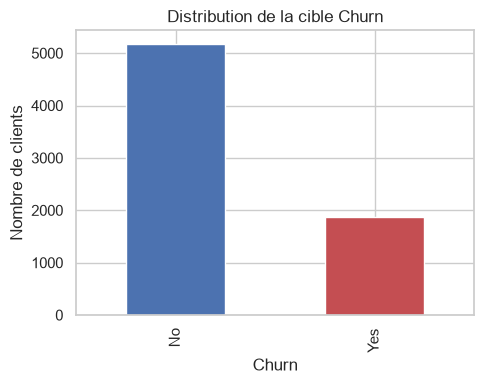

In [6]:
churn_rate = df["Churn"].mean()
print(f"Taux de churn : {churn_rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
df["Churn"].map({0: "No", 1: "Yes"}).value_counts().plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Distribution de la cible Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Nombre de clients")
plt.tight_layout()
plt.savefig(FIG_DIR / "churn_distribution.png", dpi=120)
plt.show()

Desequilibre modere (~73% / ~27%) : accuracy seule sera trompeuse, il
faudra regarder F1 / ROC-AUC / matrice de confusion.

## Distributions des variables numeriques

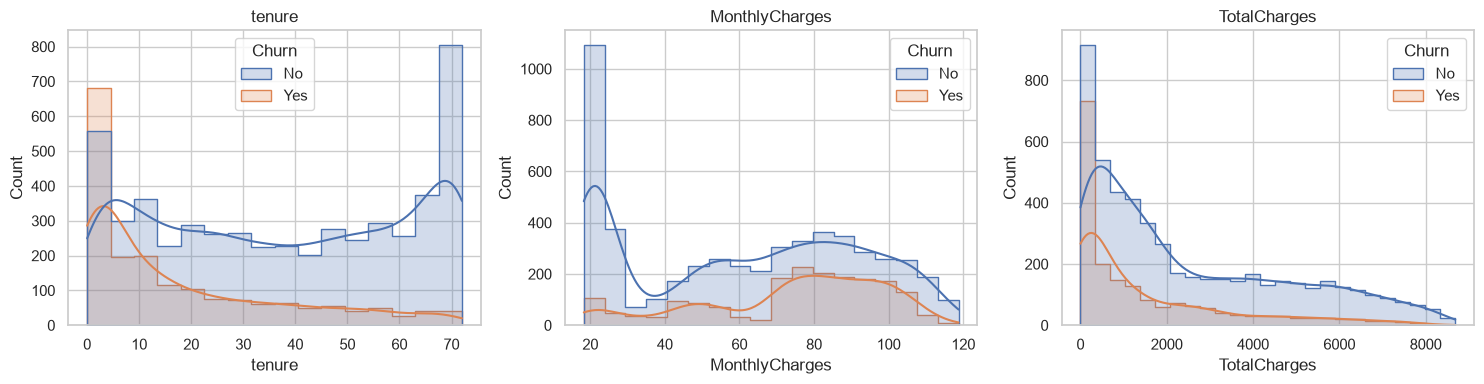

In [7]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df, x=col, hue=df["Churn"].map({0: "No", 1: "Yes"}), kde=True, ax=ax, element="step")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_distributions.png", dpi=120)
plt.show()

- `tenure` : les clients qui partent (Churn=Yes) sont fortement concentres
  sur les faibles anciennetes -- signal fort et attendu.
- `MonthlyCharges` : les clients qui partent paient en moyenne plus cher.
- `TotalCharges` correle fortement avec tenure (produit tenure x charges
  mensuelles) -- a surveiller pour la colinearite.

## Correlations (variables numeriques)

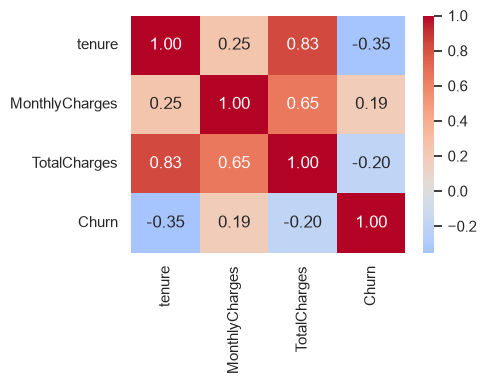

Churn             1.000000
MonthlyCharges    0.193356
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn, dtype: float64


In [8]:
corr = df[numeric_cols + ["Churn"]].corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=120)
plt.show()
print(corr["Churn"].sort_values(ascending=False))

`tenure` et `TotalCharges` sont correlees a ~0.83 (attendu : TotalCharges
~ tenure * MonthlyCharges). Les deux restent informatives individuellement
mais des modeles lineaires (regression logistique) seront sensibles a
cette colinearite -- point a garder en tete au moment de comparer les
coefficients.

## Variables categorielles vs Churn

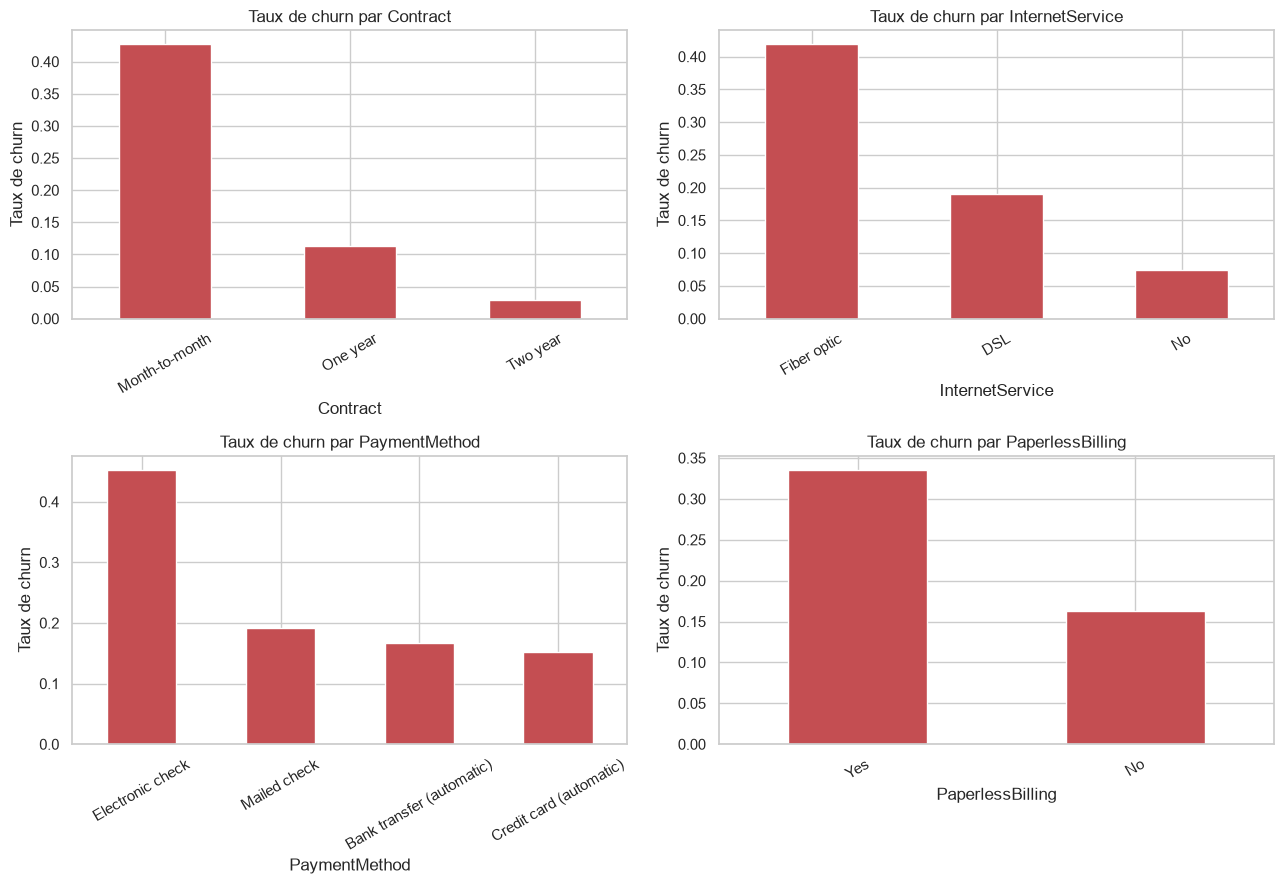

In [9]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="#C44E52")
    ax.set_title(f"Taux de churn par {col}")
    ax.set_ylabel("Taux de churn")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "categorical_churn_rates.png", dpi=120)
plt.show()

Signaux forts :
- Contrat **Month-to-month** : taux de churn nettement plus eleve que
  One year / Two year (engagement long = fidelisation).
- Service internet **Fiber optic** : churn plus eleve que DSL ou "No"
  (a investiguer -- prix plus eleve, ou qualite de service percue).
- **Electronic check** comme methode de paiement associe a un churn
  plus eleve que les paiements automatiques (carte/banque).

## Conclusions pour l'etape de nettoyage / feature engineering

1. `TotalCharges` : convertir en numerique, remplir les 11 valeurs vides
   par 0 (clients tenure=0).
2. `customerID` : a retirer (pas de valeur predictive).
3. Cible `Churn` : encoder Yes/No -> 1/0.
4. Variables categorielles : one-hot encoding.
5. Variables numeriques : standardisation (utile pour la regression
   logistique, neutre pour les modeles a base d'arbres).
6. Desequilibre de classes modere -> utiliser F1 / ROC-AUC en plus de
   l'accuracy, envisager `class_weight="balanced"` pour la regression
   logistique.